# Prevendo números da loteria com TensorFlow
Este notebook contém um exemplo de como usar o TensorFlow para prever números de loteria com base em dados anteriores.

### Carregando bibliotecas

In [36]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Carregando os dados da loteria (arquivo CSV de exemplo)

In [37]:
data = pd.read_csv('loteria_exemplo.csv', sep=';')
data.head()  # Visualizando as primeiras linhas do arquivo CSV

,X1,X2,X3,X4,X5,X6,Y1,Y2,Y3,Y4,Y5,Y6
0,43,40,19,49,44,2,48,18,26,39,2,30
1,48,18,26,39,2,30,12,32,44,18,46,6
2,12,32,44,18,46,6,11,24,30,3,48,23
3,11,24,30,3,48,23,41,49,14,1,5,10
4,41,49,14,1,5,10,1,3,24,48,25,26


### Preparando os dados para o treinamento

In [38]:
# Separando as entradas (X) e saídas (Y)
X = data[['X1', 'X2', 'X3', 'X4', 'X5', 'X6']].values  # Entradas
Y = data[['Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6']].values  # Saídas

# Normalizando os dados
X = X / 50.0  # Entradas normalizadas
Y = Y / 50.0  # Saídas normalizadas

### Definindo o modelo de rede neural

In [39]:
model = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(6,)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(6)
])

# Compilando o modelo
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mse', 'mae'])

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Treinando o modelo

In [40]:
# Treinando o modelo e salvando o histórico
history = model.fit(X, Y, epochs=500, verbose=0)

### Fazendo uma previsão

In [41]:
# Exemplo de entrada (6 números)
entrada = np.array([[5, 12, 23, 34, 45, 50]])
entrada_normalizada = entrada / 50.0  # Normalizando a entrada

# Fazendo a previsão
predicao = model.predict(entrada_normalizada)

# Convertendo de volta para a escala original (0 a 50)
predicao = predicao * 50.0
print('Números previstos:', predicao)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Números previstos: [[16.586746 29.775208 17.629246 25.851704 23.845963 20.629377]]


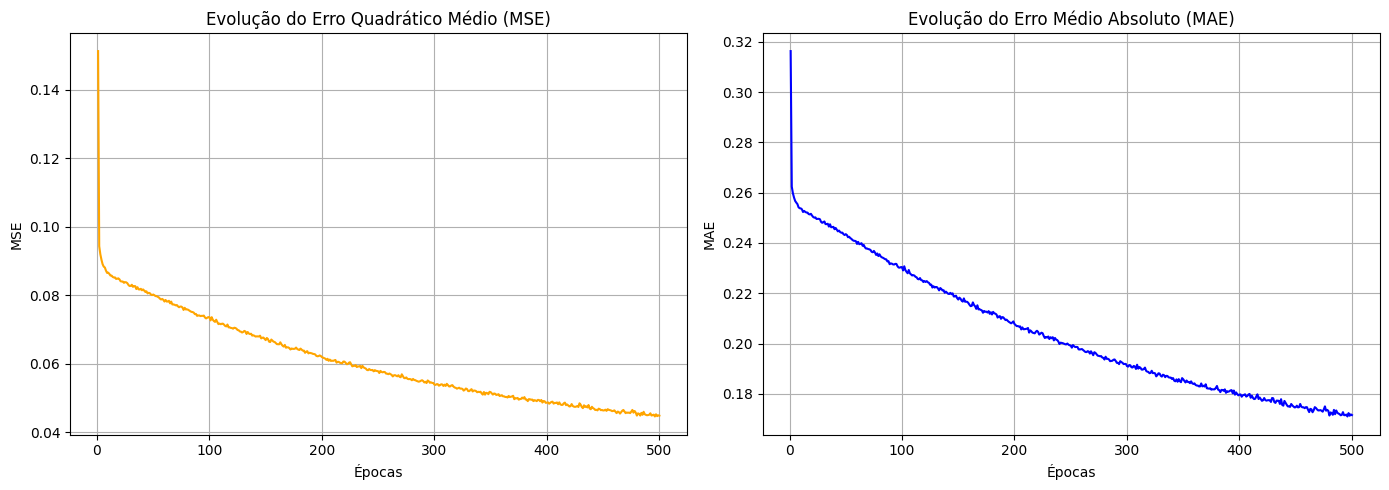

In [43]:
# Plotando a evolução do MSE e MAE ao longo das épocas
epochs = range(1, len(history.history['loss']) + 1)

# Definindo o tamanho da figura (aumentando a largura)
plt.figure(figsize=(14, 5))  # Largura 14, altura 5, ajuste conforme necessário

# Gráfico do MSE
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['mse'], label='Erro Quadrático Médio (MSE)', color='orange')
plt.title('Evolução do Erro Quadrático Médio (MSE)')
plt.xlabel('Épocas')
plt.ylabel('MSE')
plt.grid(True)

# Gráfico do MAE
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['mae'], label='Erro Médio Absoluto (MAE)', color='blue')
plt.title('Evolução do Erro Médio Absoluto (MAE)')
plt.xlabel('Épocas')
plt.ylabel('MAE')
plt.grid(True)

plt.tight_layout()
plt.show()